# Evaluación del agente de Portal Gamarrino frente al Hit Rate@3 de E5

**Equipo 7 · Capstone I · Maestría UTEC Posgrado** — notebook ejecutable en `MVP_Portal_Gamarrino/evaluacion/`

> **En una frase.** En E5 medimos el *motor de búsqueda* (embeddings) y obtuvimos un **Hit Rate@3 de 66,9 %**.
> Este notebook corre el **agente completo** sobre una **muestra aleatoria** de las mismas consultas reales y comprueba,
> con las mismas etiquetas humanas de E5, si ese número se sostiene.

**Escrito para:** el grupo que evalúa el desempeño del agente. Está pensado para poder leerse sin haber visto E5:
cada decisión de diseño está justificada en las secciones 1 y 2, y las secciones 5 a 10 son las que se ejecutan.

| Si quieres… | Ve a… |
|---|---|
| Ver el resultado y el veredicto | Sección **8** (resultados) y **10** (conclusiones de esta corrida) |
| Entender por qué se midió así y qué límites tiene | Secciones **1** y **2** |
| Repetir con otra muestra | *Run All*: **cada ejecución sortea una muestra nueva** |
| Repetir exactamente una corrida | Poner su semilla en `SEMILLA` (sección 3). La semilla de cada corrida queda impresa y guardada en el xlsx |
| Medir las 378 consultas completas | `N_MUESTRA = None` (sección 3) |
| Los archivos que deja cada corrida | Carpeta `evaluacion/resultados/` (sección 9) |

**Requisitos:** el `.venv` del proyecto (selecciónalo como kernel del notebook) y `OPENAI_API_KEY` en `MVP_Portal_Gamarrino/.env`.
Cada corrida llama a la API de OpenAI (gpt-4o-mini y embeddings); con 100 consultas el costo es de centavos.

## 1. Propósito y pregunta de evaluación

### 1.1 Qué declaramos en E5

En E5 comparamos 4 métodos sobre **378 consultas reales** de compradores, etiquetadas por el equipo.
La métrica fue **Hit Rate@3**: de todas las consultas, en qué porcentaje al menos una de las 3 tiendas propuestas era relevante.

| Método | Hit Rate@3 (ponderado) | IC 95 % |
|---|---|---|
| No hacer nada (azar) | 23,0 % | 18,8 – 27,5 |
| Lo que se hace hoy (filtro por categoría) | 46,8 % | 41,8 – 51,6 |
| Modelo simple (léxico) | 52,9 % | 48,2 – 57,7 |
| **Modelo v0 (embeddings) — el que se eligió** | **66,9 %** | **61,9 – 71,4** |

Ese 66,9 % es el número que justificó construir el prototipo con embeddings. (En la sección 5 los valores se vuelven a leer
directamente de `TABLA_FINAL_378_4metodos_ponderado.xlsx`, no se copian a mano.)

### 1.2 La pregunta

> **¿El agente real, tal como lo usaría un comprador, alcanza el Hit Rate@3 que declaramos en E5 (66,9 %, IC 95 % 61,9 – 71,4 %)?**

Responderla importa porque **E5 midió el motor de búsqueda aislado, no el agente**. Si alguna de las piezas que el agente añade
le quita aciertos, el 66,9 % de E5 no describiría el producto que realmente se entrega.

### 1.3 Qué cambia entre lo que midió E5 y el agente

| Componente | Modelo v0 de E5 | Agente real (`src/agente.py`) |
|---|---|---|
| Búsqueda | Embeddings `text-embedding-3-small` + similitud coseno sobre las 438 tiendas | Mismo modelo de embeddings, pero sobre ChromaDB y con su propio score de relevancia |
| Cuántas tiendas devuelve | Siempre el top-3 | El top-3 **solo si** el mejor score supera `UMBRAL_RELEVANCIA` (0,15); si no, la v1 avisaba que no había match confiable y la v2 **reintenta con una consulta más general** (hasta 3 búsquedas) |
| Texto de la consulta | La consulta tal cual | El LLM la reescribe antes de buscar (p. ej. corrige typos) |
| Guardrails de entrada | No existen | `DetectJailbreak` + clasificador de relevancia: pueden bloquear la consulta |
| Consultas genéricas | Se busca igual | Depende de la versión del prompt: la v1 exigía un atributo extra y **repreguntaba antes de buscar**; la v2 busca primero y solo repregunta si no se nombra ningún producto |
| Salida | Lista de 3 tiendas | Texto en español con filtro de datos personales |

### 1.4 Qué esperamos (y qué no asumimos)

No asumimos que el número se cubre. Las capas que *filtran* (guardrails, umbral, repregunta) solo pueden **quitar** aciertos al motor;
la reescritura del LLM puede sumar o restar. Por eso hay que medirlo con el mismo "examen" (las mismas etiquetas) que se usó en E5.

## 2. Diseño de la evaluación

### 2.1 La muestra: aleatoria en cada ejecución

- **Origen.** Las 378 consultas de `Muestra_378_Evaluacion/muestra_378_consultas.xlsx` (muestreo sistemático sobre las 4.000 consultas
  reales, semilla 42, definido en E5). Son **280 textos distintos**: algunos se repiten ("Polos básicos" aparece 34 veces).
- **Sorteo.** Cada ejecución elige `N_MUESTRA` de esas 378 filas, **sin reemplazo y al azar**. La semilla del sorteo se genera sola,
  se imprime y se guarda; para repetir una corrida exacta basta con fijarla en `SEMILLA`.
- **Por qué se sortea de las 378 filas y no de las 280 textos distintos.** Así las consultas frecuentes pesan según su frecuencia real,
  igual que el "ponderado" de E5, y el Hit Rate es un promedio simple directamente comparable con 66,9 %. No hace falta recalcular pesos.
- Si una consulta sale más de una vez en la muestra, el agente se ejecuta una sola vez y su resultado cuenta tantas veces como aparezca.

### 2.2 El "examen": las mismas etiquetas humanas de E5

E5 etiquetó **pares (consulta, tienda)** como Sí/No siguiendo `CRITERIOS_ETIQUETADO.md`. Aquí se reutilizan **tal cual**, unidas desde tres archivos
(`ground_truth_378_FINAL.xlsx`, `acuerdos_directos_nuevos_v0.csv` y `hoja_desempate_nuevos_v0_41filas_ETIQUETADA.xlsx`).

*Por qué:* para poder decir que un número "se cubre", el examen tiene que ser el mismo. Si se cambiara el criterio de relevancia, la comparación con E5 dejaría de ser válida.
*Límite conocido:* el acuerdo entre evaluadores en E5 fue κ = 0,627, por debajo del 0,80 que pide la rúbrica. El examen tiene ruido y ese ruido se hereda aquí.

### 2.3 Qué cuenta como acierto

Una consulta es un **acierto (Hit@3)** si, entre las tiendas que el agente finalmente muestra (hasta 3), **al menos una está etiquetada como relevante**.
Si el agente **no muestra tiendas** —lo bloquea un guardrail, repregunta, o responde "no hay match confiable"— la consulta cuenta como **fallo**:
el comprador no recibió una recomendación.

### 2.4 Dos formas de medir al agente (M1 y M2)

Una prueba preliminar mostró algo decisivo: el prompt del agente le exige *un atributo concreto además de la prenda*, así que incluso consultas como
"Vestidos" o "Polos básicos" (las más frecuentes de la muestra) **provocan una repregunta en lugar de una búsqueda**. Si solo se mide el primer turno,
el resultado mezcla dos cosas distintas: la calidad del buscador y la política conversacional del agente. Por eso se miden ambas por separado:

| Medida | Qué hace | Qué mide |
|---|---|---|
| **M1 · Primer turno** | Se evalúa solo la respuesta al primer mensaje | La experiencia del primer contacto: ¿el comprador recibe tiendas de inmediato? |
| **M2 · Con seguimiento neutro** | Si el agente repregunta *antes de buscar*, se responde **una vez** con una frase fija y neutra ("Me da igual, no tengo preferencia. Muéstrame las opciones que tengas.") y se evalúa lo que entrega | La calidad del buscador del agente sin castigarlo por repreguntar. **Es la lectura más comparable con E5**, donde el sistema siempre devolvía tiendas |

No se inventan respuestas con detalles (color, talla…) porque sería suponer la intención del comprador. El límite es que un comprador real sí
daría más detalle, lo que probablemente *ayudaría*; M2 es por tanto una medición prudente.
El seguimiento solo se usa cuando el agente repregunta sin buscar. Un bloqueo de guardrail o un "sin resultados confiables" son resultados del sistema y se dejan como están.

### 2.5 Pares sin etiqueta: cota inferior y cota superior

E5 etiquetó unos 2.900 pares. Como el agente reformula la consulta, puede mostrar tiendas que **E5 nunca etiquetó**; sin una persona no se sabe si son relevantes.
En lugar de adivinar, cada medida se reporta como un rango:

- **Cota inferior:** los pares sin etiqueta se consideran *No*.
- **Cota superior:** los pares sin etiqueta se consideran *Sí*.

El valor real está entre ambas. Los pares pendientes se exportan (sección 9) para que el equipo los etiquete con `CRITERIOS_ETIQUETADO.md` y cierre el rango.
**No se usa un LLM como juez:** en E5 se probó y coincidió con el humano solo el 51,5 % de las veces (mínimo exigido: 80 %).

### 2.6 Intervalo de confianza y veredicto

- **IC 95 %:** bootstrap no paramétrico, 1.000 remuestreos con semilla 42 — el mismo procedimiento de E5 (`RESUMEN_E5_EXPLICADO.md`, sección 5.2).
- **Veredicto sobre "¿se cubre el 66,9 %?":**

| Situación | Veredicto |
|---|---|
| 66,9 % cae dentro del IC del agente, tanto con la cota inferior como con la superior | **SE CUBRE** |
| 66,9 % queda por encima del IC de la cota superior | **NO SE CUBRE** (el agente rinde menos) |
| 66,9 % queda por debajo del IC de la cota inferior | **SUPERA E5** |
| Cualquier otro caso | **INDETERMINADO** — depende de etiquetar los pares pendientes |

- **Dato informativo adicional:** si el Hit Rate del agente cae dentro del IC de E5 (61,9 – 71,4 %).
- **Cuidado al leer "SE CUBRE" con muestras chicas:** con pocas consultas el IC es muy ancho y casi cualquier valor cae dentro. Por eso hay una segunda comparación (2.7).

### 2.7 Comparación pareada con E5 sobre la *misma* muestra

Además de comparar contra el 66,9 % global, se calcula el Hit Rate que **el modelo v0 de E5 obtiene sobre exactamente las mismas consultas sorteadas**
(con sus etiquetas ya completas). La diferencia agente − E5 elimina el ruido del sorteo y aísla el efecto de lo que el agente añade.
Además se clasifica **por qué** pierde cada consulta (guardrail, repregunta, umbral, búsqueda sin acierto).

### 2.8 Protocolo técnico (y por qué)

- Se llama a la función real **`responder()`** de `src/agente.py` (guardrails de entrada → agente → filtro de salida), no a una copia.
- **Una sesión nueva por consulta**, para que no haya memoria cruzada entre consultas.
- **`historial.db` no se toca.** Ese archivo guarda tráfico real de compradores y su feedback; `guardar_interaccion` se reemplaza por una función vacía y al final se verifica que el conteo no cambió.
- **Se registra el `store_id` de lo que la búsqueda devuelve**, envolviendo (sin alterar su resultado) la llamada a Chroma. No se puede deducir la tienda del texto de la respuesta porque el nombre no es único (352 nombres distintos para 438 tiendas).
- **LangSmith se desactiva** (`TRAZAR_EN_LANGSMITH = False`). El `.env` del proyecto tiene el trazado activo y, sin este apagado, cada corrida subiría a un servicio externo las consultas y los datos de contacto de las tiendas.
- **Teléfonos enmascarados:** los datos de contacto de las tiendas solo están autorizados para uso académico; ningún archivo exportado ni salida de este notebook los incluye.
- **Versión del agente:** cada corrida guarda una huella (hash) del `SYSTEM_PROMPT` y una nota libre (`NOTA_CORRIDA`), para saber qué versión del agente produjo cada resultado y poder comparar antes/después de un cambio.
- Las consultas se ejecutan en paralelo (`MAX_WORKERS`) y se guarda un *checkpoint* en disco, de modo que una corrida interrumpida con semilla fija se puede reanudar.

### 2.9 Límites y amenazas a la validez

1. **Etiquetas con ruido** (κ = 0,627 < 0,80), heredado de E5.
2. **Pares sin etiqueta:** el resultado es un rango, no un número único, hasta que se etiqueten.
3. **El seguimiento neutro no es un comprador real** (ver 2.4).
4. **No determinismo:** el LLM usa `temperature=0` pero eso no garantiza respuestas idénticas. Una corrida es una realización; `registro_corridas.csv` permite ver cuánto varía entre corridas.
5. **Muestra pequeña → IC ancho.** Los segmentos con menos de 30 consultas se marcan como no interpretables.
6. **Los scores de Chroma y el coseno de E5 no son comparables** entre sí (distinta transformación), por eso el umbral 0,15 no se puede leer contra los scores de E5.
7. **Es una medición offline:** no mide satisfacción de compradores reales; eso lo cubre el feedback guardado en `historial.db`.
8. **Respuestas con varias búsquedas.** Si en un mismo turno el agente busca más de una vez y presenta tiendas de varias búsquedas (p. ej. "polos y poleras" → una búsqueda por prenda), solo se evalúa la **última** búsqueda. Esas filas quedan marcadas con `captura_ok = False` y se cuentan al final de la sección 7; suelen ser una fracción pequeña de la muestra.
9. **Falsos bloqueos del guardrail de relevancia.** El clasificador LLM rechazaba consultas legítimas cortas («Short», «Maletas») y respuestas a repreguntas del propio agente; desde el 31-oct-2026 esos casos pasan por reglas deterministas (`guardrails_mvp.py`). Lo que todavía bloquea son sobre todo mensajes que no piden una prenda (ubicaciones, precios), y no es determinista. Eso baja el Hit Rate del agente y se ve en la tabla de estados de 8.1 y en las causas de 8.3; la lista de consultas bloqueadas está en la hoja `detalle_consultas` del xlsx.

## 3. Parámetros

Es la única celda pensada para editarse. Los valores por defecto producen una corrida de ~100 consultas con muestra nueva cada vez.

In [40]:
# ── Parámetros de la evaluación ────────────────────────────────────────────────────────────
N_MUESTRA = 180             # filas a sortear de las 378 (None = las 378 completas, sin azar)
SEMILLA = 35              # None = muestra NUEVA en cada ejecución | entero = reproduce una corrida anterior
SEGUIMIENTO_NEUTRO = True   # True = si el agente repregunta antes de buscar, se responde UNA vez (ver 2.4)
SEGUIMIENTO_TEXTO = "Me da igual, no tengo preferencia. Muéstrame las opciones que tengas."
MAX_WORKERS = 4             # consultas en paralelo
TRAZAR_EN_LANGSMITH = False # False = no enviar trazas a LangSmith (ver 2.8)
N_BOOTSTRAP = 1000          # remuestreos del IC 95 % (igual que E5)
SEMILLA_BOOTSTRAP = 42      # semilla del bootstrap (igual que E5). NO es la semilla del sorteo
USAR_JUEZ_LLM = True       # True = los pares sin etiqueta humana los juzga un LLM (evaluacion/juez_llm.py) → estimación provisional
NOTA_CORRIDA = ""           # texto libre que queda en el registro (p. ej. "antes del cambio de prompt")

## 4. Preparación del entorno

Aquí se importa el agente real y se instalan **dos observadores** que no cambian su comportamiento:
uno registra el `store_id` y el score de cada búsqueda en Chroma, y otro registra si un guardrail bloqueó la consulta y de qué tipo.
Además se anula `guardar_interaccion` para no escribir en `historial.db` (ver 2.8).

In [41]:
import os, sys, re, json, time, sqlite3, hashlib, warnings, logging, threading, contextvars
from pathlib import Path
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

%matplotlib inline
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
logging.getLogger("opentelemetry").setLevel(logging.CRITICAL)  # ruido de telemetría de Guardrails AI; no afecta resultados
logging.getLogger("presidio-analyzer").setLevel(logging.ERROR)  # avisos de idiomas del detector de PII; no afectan resultados
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1"); os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 70)

# ── Rutas (relativas a la raíz del proyecto, para que funcione en cualquier equipo) ─────
def _raiz_mvp():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "src" / "agente.py").exists():
            return cand
    raise FileNotFoundError("No encuentro src/agente.py: abre el notebook desde MVP_Portal_Gamarrino/evaluacion/")

RAIZ_MVP = _raiz_mvp()
DIR_E5 = RAIZ_MVP.parent / "Muestra_378_Evaluacion"        # insumos y etiquetas de E5
DIR_SALIDA = RAIZ_MVP / "evaluacion" / "resultados"        # lo que deja cada corrida
DIR_SALIDA.mkdir(parents=True, exist_ok=True)
assert DIR_E5.exists(), f"No encuentro la carpeta de E5: {DIR_E5}"

# ── Trazado externo APAGADO antes de importar el agente (el .env lo trae activo) ────────
if not TRAZAR_EN_LANGSMITH:
    os.environ["LANGSMITH_TRACING"] = "false"
    os.environ["LANGCHAIN_TRACING_V2"] = "false"

sys.path.insert(0, str(RAIZ_MVP / "src"))
import agente as A                                   # el agente real (carga .env, Chroma y guardrails)
from guardrails_mvp import GuardrailBloqueado

# ── Observador 1: contexto por consulta (seguro con hilos) ──────────────────────────────
CAP = contextvars.ContextVar("cap", default=None)

# ── Observador 2: registra qué devuelve Chroma (store_id + score) sin alterarlo ─────────
# Los originales se guardan en A la primera vez: si esta celda se re-ejecuta en el mismo kernel, A ya
# viene parchado y envolver el wrapper con otro wrapper termina en RecursionError en todas las consultas.
if not hasattr(A, "_orig_busqueda"):
    A._orig_busqueda = A._vectorstore.similarity_search_with_relevance_scores
    A._orig_verificar = A.verificar_entrada
_busqueda_original = A._orig_busqueda
def _busqueda_registrada(*args, **kwargs):
    resultados = _busqueda_original(*args, **kwargs)
    cap = CAP.get()
    if cap is not None:
        cap["busquedas"].append([
            {"store_id": d.metadata["store_id"], "display_name": d.metadata["display_name"],
             "categories": d.metadata.get("categories", ""), "subcategory": d.metadata.get("subcategory", ""),
             "gallery": d.metadata.get("gallery", ""), "floor": d.metadata.get("floor", ""),
             "stand": d.metadata.get("stand", ""), "score": float(s)}
            for d, s in resultados])
    return resultados
A._vectorstore.similarity_search_with_relevance_scores = _busqueda_registrada

# ── Observador 3: registra si un guardrail de entrada bloqueó la consulta ───────────────
_verificar_original = A._orig_verificar
def _verificar_registrando(mensaje, historial=""):
    try:
        _verificar_original(mensaje, historial)
    except GuardrailBloqueado as e:
        cap = CAP.get()
        if cap is not None:
            cap["bloqueo"] = str(e)
        raise
A.verificar_entrada = _verificar_registrando

# ── historial.db intacto: la evaluación NO debe registrarse como tráfico real ───────────
A.guardar_interaccion = lambda *args, **kwargs: -1
RUTA_HISTORIAL = RAIZ_MVP / "historial.db"
def _n_historial():
    return sqlite3.connect(RUTA_HISTORIAL).execute("select count(*) from interacciones").fetchone()[0]
N_HISTORIAL_ANTES = _n_historial()

print(f"Raíz del proyecto : {RAIZ_MVP}")
print(f"Insumos de E5     : {DIR_E5}")
print(f"Salida            : {DIR_SALIDA}")
print(f"LangSmith         : {'ACTIVO' if TRAZAR_EN_LANGSMITH else 'desactivado'}")
print(f"historial.db      : {N_HISTORIAL_ANTES} interacciones reales (no se modificarán)")
PROMPT_HASH = hashlib.sha256(A.SYSTEM_PROMPT.encode("utf-8")).hexdigest()[:10]
print(f"System prompt     : huella {PROMPT_HASH} ({len(A.SYSTEM_PROMPT)} caracteres) | nota de la corrida: {NOTA_CORRIDA or '—'}")
print(f"Umbral del agente : UMBRAL_RELEVANCIA = {A.UMBRAL_RELEVANCIA} | TOP_K = {A.TOP_K} | modelo = {A.MODELO_CHAT}")

Raíz del proyecto : D:\APRENDIZAJE\MAESTRIA\CICLO_V\CAPSTONE_I\Entregables\Entregable 29-10\MVP_Portal_Gamarrino
Insumos de E5     : D:\APRENDIZAJE\MAESTRIA\CICLO_V\CAPSTONE_I\Entregables\Entregable 29-10\Muestra_378_Evaluacion
Salida            : D:\APRENDIZAJE\MAESTRIA\CICLO_V\CAPSTONE_I\Entregables\Entregable 29-10\MVP_Portal_Gamarrino\evaluacion\resultados
LangSmith         : desactivado
historial.db      : 10 interacciones reales (no se modificarán)
System prompt     : huella a1717179aa (3582 caracteres) | nota de la corrida: —
Umbral del agente : UMBRAL_RELEVANCIA = 0.15 | TOP_K = 3 | modelo = gpt-4o-mini


## 5. Insumos de E5: consultas, etiquetas y número de referencia

Se cargan los archivos de E5 y se hacen **tres comprobaciones** antes de evaluar nada:
(1) que las tres fuentes de etiquetas no se contradigan, (2) que todos los pares del modelo v0 de E5 tengan etiqueta, y
(3) que, con este código, **se reproduzca exactamente el 66,93 % publicado en E5**. Si (3) no se cumple, algo está mal cargado y el notebook se detiene.

In [42]:
def norm_si_no(serie):
    """Misma normalización que los scripts de E5: primera letra S/N (tolera 'SÍ' con tilde)."""
    return serie.astype(str).str.strip().str.upper().str[0].map({"S": "SI", "N": "NO"})

# ── Consultas, mapa a las 378 filas y segmentos ───────────────────────────────────────
mapa = pd.read_csv(DIR_E5 / "mapa_muestra378_a_query_id.csv")                     # 378 filas: muestra_id -> query_id
consultas = pd.read_excel(DIR_E5 / "consultas_distintas_para_etiquetar.xlsx")[["query_id", "consulta"]]  # 280 textos distintos
segmentos = pd.read_csv(DIR_E5 / "segmentos_280.csv")[["query_id", "segmento"]]
print(f"Filas de la muestra de E5: {len(mapa)} | consultas distintas: {mapa.query_id.nunique()}")

# ── Etiquetas humanas: tres fuentes, mismo orden de precedencia que el script 09 de E5 ──
gt = pd.read_excel(DIR_E5 / "ground_truth_378_FINAL.xlsx")
v0 = pd.read_csv(DIR_E5 / "acuerdos_directos_nuevos_v0.csv")
des = pd.read_excel(DIR_E5 / "hoja_desempate_nuevos_v0_41filas_ETIQUETADA.xlsx")
fuentes = {
    "ground_truth_378_FINAL (3 baselines)": dict(zip(gt["key"], norm_si_no(gt["relevante_GT"]))),
    "acuerdos_directos_nuevos_v0": dict(zip(v0["key"], norm_si_no(v0["ground_truth_SiNo"]))),
    "desempate_nuevos_v0 (41 filas)": dict(zip(des["key"], norm_si_no(des["relevante_DESEMPATE_SiNo"]))),
}
ETIQ, contradicciones = {}, 0
for nombre, d in fuentes.items():
    contradicciones += sum(1 for k, v in d.items() if k in ETIQ and ETIQ[k] != v)
    ETIQ.update(d)
    print(f"  {nombre:<40} {len(d):>5} pares")
print(f"Pares etiquetados en total: {len(ETIQ)} | contradicciones entre fuentes: {contradicciones}")

# ── Etiquetas humanas de pares del AGENTE (fuera del pool de E5), cuando el equipo las cargue ──
# Mismo protocolo que E5 (doble ciego + desempate): ver evaluacion/etiquetas/consolidar_etiquetas_humanas.py
RUTA_ETQ_AGENTE = RAIZ_MVP / "evaluacion" / "etiquetas" / "etiquetas_humanas_agente.csv"
if RUTA_ETQ_AGENTE.exists():
    h = pd.read_csv(RUTA_ETQ_AGENTE, encoding="utf-8-sig").dropna(subset=["relevante_SiNo"])
    nuevas = {k: v for k, v in zip(h["key"], norm_si_no(h["relevante_SiNo"])) if k not in ETIQ}
    ETIQ.update(nuevas)
    print(f"  {'etiquetas_humanas_agente':<40} {len(nuevas):>5} pares nuevos | total: {len(ETIQ)}")

# ── Número de referencia: se LEE del archivo de E5, no se copia a mano ──────────────────
tabla_e5 = pd.read_excel(DIR_E5 / "TABLA_FINAL_378_4metodos_ponderado.xlsx")
display(tabla_e5)
ref = tabla_e5.set_index("metodo").loc["modelo_v0"]
E5_HR, E5_LO, E5_HI = float(ref["hit_rate_3"]), float(ref["ic95_lo"]), float(ref["ic95_hi"])

# ── Salida de E5 (modelo v0, offline) y comprobaciones ─────────────────────────────────
cand_v0 = pd.read_excel(DIR_E5 / "candidatos_modelo_v0_378.xlsx")
cand_v0["key"] = cand_v0["query_id"].astype(str) + "|" + cand_v0["store_id"].astype(str)
cand_v0["etq"] = cand_v0["key"].map(ETIQ)
assert cand_v0["etq"].notna().all(), "Hay pares del modelo v0 de E5 sin etiqueta: revisar los archivos de etiquetas"
E5_HIT_POR_QUERY = {q: int((g["etq"] == "SI").any()) for q, g in cand_v0.groupby("query_id")}
E5_TOP3_POR_QUERY = {q: set(g["store_id"]) for q, g in cand_v0.groupby("query_id")}

reproducido = mapa["query_id"].map(E5_HIT_POR_QUERY).mean() * 100
print(f"\nHit Rate@3 del modelo v0 de E5 recalculado aquí sobre las 378 filas: {reproducido:.2f} %  (publicado: {E5_HR:.2f} %)")
assert abs(reproducido - E5_HR) < 0.01, "No se reproduce el número de E5: las etiquetas o el mapa no están bien cargados"
print("✔ El número de E5 se reproduce exactamente: el 'examen' está bien cargado.")

Filas de la muestra de E5: 378 | consultas distintas: 280
  ground_truth_378_FINAL (3 baselines)      2299 pares
  acuerdos_directos_nuevos_v0                604 pares
  desempate_nuevos_v0 (41 filas)              41 pares
Pares etiquetados en total: 2944 | contradicciones entre fuentes: 0


,metodo,n,hit_rate_3,ic95_lo,ic95_hi
0,no_hacer_nada,378,23.02,18.78,27.51
1,lo_que_se_hace_hoy_categoria,378,46.83,41.80,51.59
2,modelo_simple_lexico,378,52.91,48.15,57.67
3,modelo_v0,378,66.93,61.90,71.43



Hit Rate@3 del modelo v0 de E5 recalculado aquí sobre las 378 filas: 66.93 %  (publicado: 66.93 %)
✔ El número de E5 se reproduce exactamente: el 'examen' está bien cargado.


## 6. Sorteo de la muestra

Se genera la semilla del sorteo (o se usa la de `SEMILLA`), se eligen las filas y se muestra qué quedó dentro.
**Anota la semilla impresa abajo:** es lo que permite repetir exactamente esta corrida.

In [43]:
semilla_usada = int(np.random.SeedSequence().entropy % (2**32)) if SEMILLA is None else int(SEMILLA)
rng_sorteo = np.random.default_rng(semilla_usada)

if N_MUESTRA is None or N_MUESTRA >= len(mapa):
    muestra = mapa.copy()
    descripcion_muestra = f"las {len(mapa)} filas completas (sin azar)"
else:
    idx = np.sort(rng_sorteo.choice(len(mapa), size=int(N_MUESTRA), replace=False))
    muestra = mapa.iloc[idx].copy()
    descripcion_muestra = f"{len(muestra)} filas sorteadas al azar de {len(mapa)}"

muestra = (muestra.merge(consultas, on="query_id", how="left")
                  .merge(segmentos, on="query_id", how="left")
                  .reset_index(drop=True))
unicas = muestra[["query_id", "consulta"]].drop_duplicates().sort_values("query_id").reset_index(drop=True)

TS = datetime.now().strftime("%Y%m%d_%H%M%S")
PREFIJO = DIR_SALIDA / f"corrida_{TS}_semilla{semilla_usada}"

print(f"SEMILLA DEL SORTEO: {semilla_usada}   ← pégala en SEMILLA (sección 3) para repetir esta corrida")
print(f"Muestra: {descripcion_muestra} → {muestra.query_id.nunique()} consultas distintas a ejecutar\n")
display(muestra["segmento"].value_counts().rename("filas").to_frame().assign(
    porcentaje=lambda d: (d["filas"] / len(muestra) * 100).round(1)))
print("Consultas más repetidas en esta muestra:")
display(muestra["consulta"].value_counts().head(5).rename("veces").to_frame())

SEMILLA DEL SORTEO: 35   ← pégala en SEMILLA (sección 3) para repetir esta corrida
Muestra: 180 filas sorteadas al azar de 378 → 138 consultas distintas a ejecutar



,filas,porcentaje
segmento,,
Especifica (una prenda),111,61.7
Ambigua o compuesta,55,30.6
"Con marca, talla o precio",14,7.8


Consultas más repetidas en esta muestra:


,veces
consulta,
Polos básicos,17
Vestidos,6
Casacas,6
Blazer para mujer,5
Ternos,4


## 7. Ejecución del agente

Para cada consulta distinta se llama a `responder()` en una **sesión nueva**. Después de cada turno se lee el estado de la conversación para clasificar lo ocurrido:

| Estado | Cómo se detecta | ¿El comprador recibe tiendas? |
|---|---|---|
| `recomendo_tiendas` | El agente llamó a la herramienta y esta devolvió tiendas | Sí |
| `pidio_aclaracion` | El agente respondió **sin** llamar a la herramienta (repregunta) | No |
| `sin_resultados_confiables` | La herramienta devolvió `BUSQUEDA_SIN_RESULTADOS_CONFIABLES` (score bajo el umbral) | No |
| `bloqueada_guardrail` | Un guardrail de entrada lanzó `GuardrailBloqueado` (se distingue *relevancia* de *seguridad*) | No |
| `error` | Falló la ejecución dos veces seguidas (red, API…) | No; se reporta aparte |

Como control de calidad de la captura, para cada turno se comprueba que **las tiendas registradas coincidan con las que el agente leyó** (`captura_ok`).
Los textos de respuesta se guardan con los teléfonos enmascarados.

In [44]:
TELEFONO = re.compile(r"\+?\d[\d\s\-().]{7,}\d")
def ocultar_telefonos(texto):
    """Los contactos reales de las tiendas solo están autorizados para uso académico: nunca se guardan."""
    return TELEFONO.sub("[tel. oculto]", texto)

def _turno(mensaje, session_id):
    """Un turno de conversación con el agente real, más lo que hay que observar de él."""
    cap = {"busquedas": [], "bloqueo": None}
    CAP.set(cap)
    texto, _ = A.responder(mensaje, session_id)           # ← la función real del producto

    tool_msgs = []
    if cap["bloqueo"] is None:                            # mensajes de herramienta de ESTE turno
        estado_graf = A.agente.get_state({"configurable": {"thread_id": session_id}})
        msgs = estado_graf.values.get("messages", []) if estado_graf.values else []
        ult_humano = max((i for i, m in enumerate(msgs) if m.type == "human"), default=-1)
        tool_msgs = [m.content for m in msgs[ult_humano + 1:] if m.type == "tool"]

    if cap["bloqueo"] is not None:
        estado = "bloqueada_guardrail"
    elif not tool_msgs:
        estado = "pidio_aclaracion"
    elif tool_msgs[-1].startswith("BUSQUEDA_SIN_RESULTADOS_CONFIABLES"):
        estado = "sin_resultados_confiables"
    else:
        estado = "recomendo_tiendas"

    top3 = cap["busquedas"][-1] if cap["busquedas"] else []   # la última búsqueda es la que sustenta la respuesta
    captura_ok = len(cap["busquedas"]) == len(tool_msgs) and (
        estado != "recomendo_tiendas" or all(t["display_name"] in tool_msgs[-1] for t in top3))
    bloqueo_tipo = None if cap["bloqueo"] is None else (
        "seguridad" if cap["bloqueo"].startswith("No puedo procesar") else "relevancia")   # DetectJailbreak vs. clasificador de relevancia
    return {"estado": estado, "respuesta": ocultar_telefonos(texto)[:2000], "top3": top3,
            "captura_ok": captura_ok, "bloqueo_tipo": bloqueo_tipo, "n_busquedas": len(cap["busquedas"])}

def evaluar_consulta(query_id, consulta):
    t0, ultimo_error = time.time(), None
    for intento in (1, 2):                                # un reintento ante fallos transitorios de red/API
        try:
            sid = f"eval-{semilla_usada}-{query_id}-i{intento}"
            t1 = _turno(consulta, sid)
            t2 = _turno(SEGUIMIENTO_TEXTO, sid) if (SEGUIMIENTO_NEUTRO and t1["estado"] == "pidio_aclaracion") else None
            fin = t2 or t1
            return {"query_id": query_id, "consulta": consulta,
                    "t1_estado": t1["estado"], "t1_bloqueo": t1["bloqueo_tipo"], "t1_respuesta": t1["respuesta"], "t1_top3": t1["top3"],
                    "t2_estado": t2["estado"] if t2 else None, "t2_respuesta": t2["respuesta"] if t2 else None,
                    "final_estado": fin["estado"], "final_top3": fin["top3"], "final_respuesta": fin["respuesta"],
                    "captura_ok": t1["captura_ok"] and (t2 is None or t2["captura_ok"]),
                    "n_busquedas": t1["n_busquedas"] + (t2["n_busquedas"] if t2 else 0),
                    "error": None, "segundos": round(time.time() - t0, 1)}
        except Exception as e:
            ultimo_error = f"{type(e).__name__}: {str(e)[:200]}"
            time.sleep(2)
    return {"query_id": query_id, "consulta": consulta, "t1_estado": "error", "t1_bloqueo": None, "t1_respuesta": "", "t1_top3": [],
            "t2_estado": None, "t2_respuesta": None, "final_estado": "error", "final_top3": [], "final_respuesta": "",
            "captura_ok": True, "n_busquedas": 0, "error": ultimo_error, "segundos": round(time.time() - t0, 1)}

# ── Checkpoint: si la corrida se interrumpe y se repite con la misma SEMILLA, retoma donde quedó ──
RUTA_CKPT = DIR_SALIDA / f"_checkpoint_semilla{semilla_usada}_seg{int(SEGUIMIENTO_NEUTRO)}.jsonl"
resultados = {}
if RUTA_CKPT.exists():
    for linea in RUTA_CKPT.read_text(encoding="utf-8").splitlines():
        r = json.loads(linea)
        if r["final_estado"] != "error":
            resultados[r["query_id"]] = r
    print(f"Checkpoint encontrado: se retoman {len(resultados)} consultas ya ejecutadas")

pendientes = [(q, c) for q, c in unicas.itertuples(index=False) if q not in resultados]
candado = threading.Lock()
def _tarea(q, c):
    r = evaluar_consulta(q, c)
    with candado, open(RUTA_CKPT, "a", encoding="utf-8") as f:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")
    return r

t_ini = time.time()
print(f"Ejecutando {len(pendientes)} consultas con {MAX_WORKERS} en paralelo...")
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
    futuros = [ex.submit(_tarea, q, c) for q, c in pendientes]
    for i, fut in enumerate(as_completed(futuros), 1):
        r = fut.result()
        resultados[r["query_id"]] = r
        if i % 10 == 0 or i == len(futuros):
            print(f"  {i}/{len(futuros)}  ({time.time() - t_ini:.0f} s)")

n_err = sum(r["final_estado"] == "error" for r in resultados.values())
n_inconsistentes = sum(not r["captura_ok"] for r in resultados.values())
print(f"\nListo en {time.time() - t_ini:.0f} s | errores de ejecución: {n_err} | capturas inconsistentes: {n_inconsistentes}")
if n_err or n_inconsistentes:
    print("⚠ Revisar: los errores cuentan como fallo del agente y las capturas inconsistentes pueden sesgar la puntuación.")

Ejecutando 138 consultas con 4 en paralelo...
  10/138  (21 s)
  20/138  (34 s)
  30/138  (47 s)
  40/138  (65 s)
  50/138  (78 s)
  60/138  (89 s)
  70/138  (106 s)
  80/138  (118 s)
  90/138  (132 s)
  100/138  (146 s)
  110/138  (161 s)
  120/138  (175 s)
  130/138  (189 s)
  138/138  (199 s)

Listo en 199 s | errores de ejecución: 0 | capturas inconsistentes: 0


In [45]:
# ── Juez LLM (provisional) para los pares que siguen sin etiqueta humana ───────────────────
# Las etiquetas humanas mandan siempre; el juez solo da la estimación puntual mientras el equipo
# etiqueta esos pares. Su acuerdo con las etiquetas humanas: etiquetas/validacion_juez_llm_resumen.json
ETIQ_JUEZ, KAPPA_JUEZ, MODELO_JUEZ = {}, None, None
if USAR_JUEZ_LLM:
    sys.path.insert(0, str(RAIZ_MVP / "evaluacion"))
    import juez_llm
    MODELO_JUEZ = juez_llm.MODELO_JUEZ
    pares_juez = pd.DataFrame([{"key": f"{r['query_id']}|{t['store_id']}", "consulta": r["consulta"], **t}
                               for r in resultados.values() for t in r["t1_top3"] + r["final_top3"]])
    if len(pares_juez):
        ETIQ_JUEZ = juez_llm.juzgar(pares_juez[~pares_juez["key"].isin(ETIQ.keys())].drop_duplicates("key"))
    ruta_val = juez_llm.DIR_ETIQUETAS / "validacion_juez_llm_resumen.json"
    if ruta_val.exists():
        KAPPA_JUEZ = json.loads(ruta_val.read_text(encoding="utf-8"))["modelos"].get(MODELO_JUEZ, {}).get("kappa_vs_etiqueta_humana_final")
    print(f"Juez LLM ({MODELO_JUEZ}): {len(ETIQ_JUEZ)} pares sin etiqueta humana juzgados "
          f"({sum(v == 'SI' for v in ETIQ_JUEZ.values())} SÍ) | κ vs. etiquetas humanas: {KAPPA_JUEZ if KAPPA_JUEZ is not None else 'sin validar'}")


Juez LLM (gpt-4o): 128 pares sin etiqueta humana juzgados (34 SÍ) | κ vs. etiquetas humanas: 0.486


## 8. Resultados

### 8.1 Qué hizo el agente con cada consulta

Cada fila de la muestra cuenta (una consulta frecuente pesa más). **M1** es el estado tras el primer mensaje; **M2** el estado final tras el seguimiento neutro (si estaba activado).

In [46]:
# ── Puntuación de cada consulta contra las etiquetas de E5 ───────────────────────────────
def etiquetas_de(query_id, top3):
    return [ETIQ.get(f"{query_id}|{t['store_id']}") for t in top3]        # 'SI' | 'NO' | None (sin etiqueta)

def puntuar(query_id, estado, top3):
    """(acierto cota inferior, acierto cota superior, estimación con juez LLM, etiquetas). Sin tiendas
    mostradas = fallo en las tres. La estimación usa la etiqueta humana si existe y, si no, la del juez."""
    etq = etiquetas_de(query_id, top3)
    if estado != "recomendo_tiendas":
        return 0, 0, 0, etq
    est = [e if e is not None else ETIQ_JUEZ.get(f"{query_id}|{t['store_id']}") for e, t in zip(etq, top3)]
    return int(any(e == "SI" for e in etq)), int(any(e in ("SI", None) for e in etq)), int(any(e == "SI" for e in est)), etq

def causa_m2(r):
    if r["final_estado"] == "bloqueada_guardrail":      return "Bloqueada por guardrail"
    if r["final_estado"] == "error":                    return "Error de ejecución"
    if r["final_estado"] == "pidio_aclaracion":         return "Repregunta sin buscar"
    if r["final_estado"] == "sin_resultados_confiables":return "Umbral: 'sin resultados confiables'"
    if r["m2_inf"] == 1:                                return "Acierto"
    if r["m2_sup"] == 1:                                return "Pendiente: tiendas sin etiqueta"
    return "Recomendó, pero ninguna tienda es relevante"

registros = []
for r in resultados.values():
    qid = r["query_id"]
    m1_inf, m1_sup, m1_est, _ = puntuar(qid, r["t1_estado"], r["t1_top3"])
    m2_inf, m2_sup, m2_est, etq_f = puntuar(qid, r["final_estado"], r["final_top3"])
    recomendo = r["final_estado"] == "recomendo_tiendas"
    registros.append({
        "query_id": qid, "t1_estado": r["t1_estado"], "t1_bloqueo": r["t1_bloqueo"], "final_estado": r["final_estado"],
        "m1_inf": m1_inf, "m1_sup": m1_sup, "m2_inf": m2_inf, "m2_sup": m2_sup, "m1_est": m1_est, "m2_est": m2_est,
        "e5_hit": int(E5_HIT_POR_QUERY[qid]),
        "mismo_top3_e5": (set(t["store_id"] for t in r["final_top3"]) == E5_TOP3_POR_QUERY[qid]) if recomendo else None,
        "n_tiendas_sin_etiqueta": sum(e is None for e in etq_f) if recomendo else 0,
        # contrafactual: ¿el top-3 que el umbral descartó sí tenía una tienda relevante (con etiqueta conocida)?
        "umbral_descarto_acierto": int(any(e == "SI" for e in etq_f)) if r["final_estado"] == "sin_resultados_confiables" else 0,
        "captura_ok": r["captura_ok"], "n_busquedas": r.get("n_busquedas", np.nan),
    })
df_q = pd.DataFrame(registros)
df_q["causa_m2"] = df_q.apply(causa_m2, axis=1)
filas = muestra.merge(df_q, on="query_id", how="left")           # una fila por cada fila de la muestra (pondera por frecuencia)
assert len(filas) == len(muestra) and filas["final_estado"].notna().all()

nombres_estado = {"recomendo_tiendas": "Recomendó tiendas", "pidio_aclaracion": "Pidió aclaración (sin buscar)",
                  "sin_resultados_confiables": "Sin resultados confiables (umbral)", "bloqueada_guardrail": "Bloqueada por guardrail",
                  "error": "Error de ejecución"}
tabla_estados = pd.DataFrame({"M1 · primer turno": filas["t1_estado"].value_counts(),
                              "M2 · estado final": filas["final_estado"].value_counts()}
                             ).reindex(list(nombres_estado)).fillna(0).astype(int)
for c in list(tabla_estados.columns):
    tabla_estados[c + " (%)"] = (tabla_estados[c] / len(filas) * 100).round(1)
tabla_estados.index = [nombres_estado[i] for i in tabla_estados.index]
display(tabla_estados) 

if filas["n_busquedas"].notna().any():
    amp = filas[filas["n_busquedas"] > 1]
    print(f"Búsquedas ampliadas (el agente reintentó con una consulta más general): {len(amp)} filas ({len(amp) / len(filas) * 100:.0f} %), "
          f"de las cuales terminaron recomendando tiendas: {int((amp['final_estado'] == 'recomendo_tiendas').sum())}.")
bloq = filas[filas["t1_estado"] == "bloqueada_guardrail"]["t1_bloqueo"].value_counts()
if len(bloq):
    print("Bloqueos por tipo de guardrail:", bloq.to_dict())

,M1 · primer turno,M2 · estado final,M1 · primer turno (%),M2 · estado final (%)
Recomendó tiendas,169,173,93.9,96.1
Pidió aclaración (sin buscar),7,1,3.9,0.6
Sin resultados confiables (umbral),1,2,0.6,1.1
Bloqueada por guardrail,3,4,1.7,2.2
Error de ejecución,0,0,0.0,0.0


Búsquedas ampliadas (el agente reintentó con una consulta más general): 11 filas (6 %), de las cuales terminaron recomendando tiendas: 11.
Bloqueos por tipo de guardrail: {'relevancia': 3}


### 8.2 Hit Rate@3 del agente y veredicto

El Hit Rate se calcula sobre **todas las filas de la muestra** (los fallos sin tiendas cuentan como 0) y se reporta entre sus dos cotas (ver 2.5), con el IC 95 % por bootstrap de 2.6.
La referencia es el número de E5 leído en la sección 5.

### Veredicto de esta corrida — semilla `35`, 180 filas (138 consultas distintas)

Número de E5 a cubrir: **66,9 %** (IC 95 % 61,9 % – 71,4 %)

| Medida | Hit Rate@3 (cota inf. – cota sup.) | IC 95 % (extremo a extremo) | ¿Dentro del IC de E5? (inf. / sup.) | Veredicto |
|---|---|---|---|---|
| **M2 · con seguimiento neutro** (comparable con E5) | 62,2 % – 86,1 % | 55,5 % – 90,6 % | sí / no | **SE CUBRE** |
| M1 · primer turno | 61,7 % – 83,9 % | 54,4 % – 88,9 % | no / no | **SE CUBRE** |
| **M2 · estimación con juez LLM** (provisional) | 67,2 % | 60,0 % – 73,9 % | sí | **SE CUBRE** |
| M1 · estimación con juez LLM (provisional) | 66,7 % | 60,0 % – 73,9 % | sí | **SE CUBRE** |
| *Modelo v0 de E5 sobre esta misma muestra (offline)* | 66,7 % | 60,0 % – 73,3 % | sí | — |

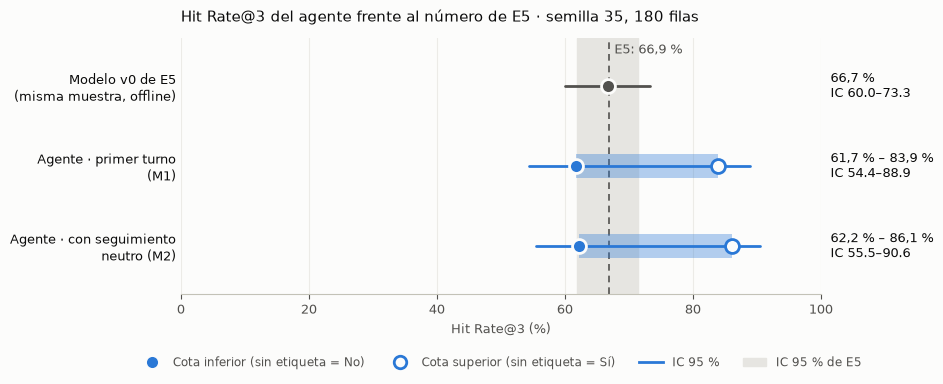

In [47]:
def hr_ic(arr):
    """Hit Rate (%) + IC 95 % por bootstrap no paramétrico. Mismo procedimiento y semilla que E5."""
    arr = np.asarray(arr, dtype=float); n = len(arr)
    rng = np.random.default_rng(SEMILLA_BOOTSTRAP)
    boot = np.array([arr[rng.integers(0, n, n)].mean() for _ in range(N_BOOTSTRAP)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return arr.mean() * 100, lo * 100, hi * 100

def pct(x, d=1):
    return f"{x:.{d}f}".replace(".", ",") + " %"

def veredicto(inf, sup):
    if E5_HR > sup[2]:              return "NO SE CUBRE (el agente rinde menos que E5)"
    if E5_HR < inf[1]:              return "SUPERA E5 (el agente rinde más que E5)"
    if inf[1] <= E5_HR <= inf[2]:   return "SE CUBRE"          # el peor caso ya cubre; el mejor cubre o supera
    return "INDETERMINADO (depende de etiquetar los pares pendientes)"

res = {"E5": hr_ic(filas["e5_hit"])}
for clave, col in [("M1 inf", "m1_inf"), ("M1 sup", "m1_sup"), ("M2 inf", "m2_inf"), ("M2 sup", "m2_sup"), ("M1 est", "m1_est"), ("M2 est", "m2_est")]:
    res[clave] = hr_ic(filas[col])
ver_m1, ver_m2 = veredicto(res["M1 inf"], res["M1 sup"]), veredicto(res["M2 inf"], res["M2 sup"])
ver_m1_est, ver_m2_est = veredicto(res["M1 est"], res["M1 est"]), veredicto(res["M2 est"], res["M2 est"])
dentro_ic_e5 = lambda x: "sí" if E5_LO <= x <= E5_HI else "no"

lineas = [f"### Veredicto de esta corrida — semilla `{semilla_usada}`, {len(filas)} filas ({filas.query_id.nunique()} consultas distintas)", "",
          f"Número de E5 a cubrir: **{pct(E5_HR)}** (IC 95 % {pct(E5_LO)} – {pct(E5_HI)})", "",
          "| Medida | Hit Rate@3 (cota inf. – cota sup.) | IC 95 % (extremo a extremo) | ¿Dentro del IC de E5? (inf. / sup.) | Veredicto |",
          "|---|---|---|---|---|"]
for nombre, k, v in [("**M2 · con seguimiento neutro** (comparable con E5)", "M2", ver_m2), ("M1 · primer turno", "M1", ver_m1)]:
    i, s = res[f"{k} inf"], res[f"{k} sup"]
    lineas.append(f"| {nombre} | {pct(i[0])} – {pct(s[0])} | {pct(i[1])} – {pct(s[2])} | {dentro_ic_e5(i[0])} / {dentro_ic_e5(s[0])} | **{v}** |")
if USAR_JUEZ_LLM:
    for nombre, k, v in [("**M2 · estimación con juez LLM** (provisional)", "M2 est", ver_m2_est), ("M1 · estimación con juez LLM (provisional)", "M1 est", ver_m1_est)]:
        lineas.append(f"| {nombre} | {pct(res[k][0])} | {pct(res[k][1])} – {pct(res[k][2])} | {dentro_ic_e5(res[k][0])} | **{v}** |")
lineas.append(f"| *Modelo v0 de E5 sobre esta misma muestra (offline)* | {pct(res['E5'][0])} | {pct(res['E5'][1])} – {pct(res['E5'][2])} | {dentro_ic_e5(res['E5'][0])} | — |")
display(Markdown("\n".join(lineas)))
if len(filas) < 150:
    display(Markdown(f"> ⚠ Con {len(filas)} filas el IC es ancho (±{(res['M2 inf'][2]-res['M2 inf'][1])/2:.0f} pp): un 'SE CUBRE' aquí es poco exigente. "
                     "Mira también la comparación pareada de la sección 8.3, que no depende de ese ancho."))

# ── Gráfico: el agente frente a la banda de E5 ────────────────────────────────────────────
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
SUPERFICIE, TINTA, TINTA_2, ACENTO, BANDA = "#fcfcfb", "#0b0b0b", "#52514e", "#2a78d6", "#e6e5e1"
fig, ax = plt.subplots(figsize=(10, 4.2), facecolor=SUPERFICIE)
ax.set_facecolor(SUPERFICIE)
ax.axvspan(E5_LO, E5_HI, color=BANDA, zorder=0)
ax.axvline(E5_HR, color=TINTA_2, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.text(E5_HR + 0.8, 2.45, f"E5: {pct(E5_HR)}", ha="left", va="center", fontsize=9, color=TINTA_2)

filas_graf = [("Modelo v0 de E5\n(misma muestra, offline)", res["E5"], None, TINTA_2),
              ("Agente · primer turno\n(M1)", res["M1 inf"], res["M1 sup"], ACENTO),
              ("Agente · con seguimiento\nneutro (M2)", res["M2 inf"], res["M2 sup"], ACENTO)]
for i, (etiqueta, a, b, color) in enumerate(filas_graf):
    y = len(filas_graf) - 1 - i
    fin = a if b is None else b
    ax.plot([a[1], fin[2]], [y, y], color=color, lw=2, solid_capstyle="round", zorder=3)               # IC 95 %
    if b is not None:
        ax.barh(y, b[0] - a[0], left=a[0], height=0.30, color=color, alpha=0.35, zorder=2)             # rango por pares sin etiqueta
        ax.plot(b[0], y, "o", ms=10, mfc=SUPERFICIE, mec=color, mew=2, zorder=5)                       # cota superior (vacío)
    ax.plot(a[0], y, "o", ms=10, color=color, mec=SUPERFICIE, mew=2, zorder=4)                         # cota inferior / valor
    valor = pct(a[0]) if b is None else f"{pct(a[0])} – {pct(b[0])}"
    ax.text(1.015, y, f"{valor}\nIC {a[1]:.1f}–{fin[2]:.1f}", transform=ax.get_yaxis_transform(),
            va="center", ha="left", fontsize=9, color=TINTA)
ax.set_yticks(range(len(filas_graf))); ax.set_yticklabels([f[0] for f in filas_graf][::-1], fontsize=9.5, color=TINTA)
ax.set_xlim(0, 100); ax.set_ylim(-0.6, 2.6)
ax.set_xlabel("Hit Rate@3 (%)", fontsize=9.5, color=TINTA_2)
ax.tick_params(axis="x", colors=TINTA_2, labelsize=9); ax.tick_params(axis="y", length=0)
for lado in ("top", "right", "left"): ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.grid(axis="x", color="#ecebe7", lw=0.8, zorder=0); ax.set_axisbelow(True)
ax.set_title(f"Hit Rate@3 del agente frente al número de E5 · semilla {semilla_usada}, {len(filas)} filas",
             loc="left", fontsize=11, color=TINTA, pad=12)
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=9, color=ACENTO, mec=SUPERFICIE, label="Cota inferior (sin etiqueta = No)"),
                   Line2D([], [], marker="o", ls="", ms=9, mfc=SUPERFICIE, mec=ACENTO, mew=2, label="Cota superior (sin etiqueta = Sí)"),
                   Line2D([], [], color=ACENTO, lw=2, label="IC 95 %"),
                   Patch(color=BANDA, label="IC 95 % de E5")],
          loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False, fontsize=8.5, labelcolor=TINTA_2)
fig.subplots_adjust(left=0.2, right=0.84, bottom=0.27, top=0.88)
RUTA_GRAFICO = Path(str(PREFIJO) + "_grafico.png")
fig.savefig(RUTA_GRAFICO, dpi=150, facecolor=SUPERFICIE)
plt.show()

### 8.3 Comparación pareada con E5 sobre la misma muestra y dónde se pierden los aciertos

El 66,9 % de E5 es un promedio sobre las 378 filas; una muestra más chica puede dar otro valor *solo por azar de muestreo*. La forma limpia de aislar el efecto del agente
es comparar, **fila por fila, contra lo que el modelo v0 de E5 hizo con esas mismas consultas**. La diferencia (agente − E5) ya no depende de qué tan fáciles o difíciles salieron las consultas sorteadas.

In [48]:
# ── Diferencia pareada agente − E5 (puntos porcentuales) ───────────────────────────────────
dif = {k: hr_ic(filas[col] - filas["e5_hit"]) for k, col in [("M1 inf", "m1_inf"), ("M1 sup", "m1_sup"), ("M2 inf", "m2_inf"), ("M2 sup", "m2_sup"), ("M1 est", "m1_est"), ("M2 est", "m2_est")]}
tabla_dif = pd.DataFrame([{
    "Medida": ("M2 · con seguimiento" if k.startswith("M2") else "M1 · primer turno") + {"inf": " · cota inf.", "sup": " · cota sup.", "est": " · estimación juez LLM"}[k[-3:]],
    "Diferencia vs E5 (pp)": round(v[0], 1), "IC 95 % inf": round(v[1], 1), "IC 95 % sup": round(v[2], 1),
    "Lectura": "el agente pierde aciertos" if v[2] < 0 else ("el agente gana aciertos" if v[1] > 0 else "diferencia no distinguible de cero"),
} for k, v in dif.items()])
display(tabla_dif)

pierde = int(((filas["e5_hit"] == 1) & (filas["m2_inf"] == 0)).sum()); gana = int(((filas["e5_hit"] == 0) & (filas["m2_inf"] == 1)).sum())
print(f"Filas donde E5 acierta y el agente (M2, cota inf.) no: {pierde} | donde el agente acierta y E5 no: {gana}")
rec = filas[filas["final_estado"] == "recomendo_tiendas"]
if len(rec):
    print(f"Cuando el agente recomendó tiendas, su top-3 fue IDÉNTICO al del modelo v0 de E5 en {rec['mismo_top3_e5'].astype(float).mean()*100:.0f} % de las filas "
          f"({int(rec['mismo_top3_e5'].astype(float).sum())}/{len(rec)}): el resto se debe a que el LLM reescribió la consulta antes de buscar.")

# ── Por qué falla cada consulta (estado final, M2) ──────────────────────────────────────────
causas = (filas.groupby("causa_m2").agg(filas=("query_id", "size"), de_ellas_E5_acierta=("e5_hit", "sum")).reset_index()
          .sort_values("filas", ascending=False))
causas["% de la muestra"] = (causas["filas"] / len(filas) * 100).round(1)
causas = causas.rename(columns={"causa_m2": "Resultado final del agente (M2)", "filas": "Filas"})
display(causas.reset_index(drop=True))

ums = filas[filas["final_estado"] == "sin_resultados_confiables"]
if len(ums):
    n_sup = int(ums.umbral_descarto_acierto.sum())
    print(f"Umbral de relevancia ({A.UMBRAL_RELEVANCIA}): suprimió el top-3 en {len(ums)} filas; en {n_sup} de ellas "
          f"ese top-3 descartado SÍ contenía una tienda relevante (etiqueta conocida)" + (" → falsos negativos del umbral." if n_sup else "."))

,Medida,Diferencia vs E5 (pp),IC 95 % inf,IC 95 % sup,Lectura
0,M1 · primer turno · cota inf.,-5.0,-8.3,-2.2,el agente pierde aciertos
1,M1 · primer turno · cota sup.,17.2,11.1,22.8,el agente gana aciertos
2,M2 · con seguimiento · cota inf.,-4.4,-7.8,-1.1,el agente pierde aciertos
3,M2 · con seguimiento · cota sup.,19.4,13.3,25.6,el agente gana aciertos
4,M1 · primer turno · estimación juez LLM,0.0,-3.3,3.9,diferencia no distinguible de cero
5,M2 · con seguimiento · estimación juez LLM,0.6,-3.3,4.4,diferencia no distinguible de cero


Filas donde E5 acierta y el agente (M2, cota inf.) no: 9 | donde el agente acierta y E5 no: 1
Cuando el agente recomendó tiendas, su top-3 fue IDÉNTICO al del modelo v0 de E5 en 40 % de las filas (70/173): el resto se debe a que el LLM reescribió la consulta antes de buscar.


,Resultado final del agente (M2),Filas,de_ellas_E5_acierta,% de la muestra
0,Acierto,112,111,62.2
1,Pendiente: tiendas sin etiqueta,43,7,23.9
2,"Recomendó, pero ninguna tienda es relevante",18,0,10.0
3,Bloqueada por guardrail,4,1,2.2
4,Umbral: 'sin resultados confiables',2,1,1.1
5,Repregunta sin buscar,1,0,0.6


Umbral de relevancia (0.15): suprimió el top-3 en 2 filas; en 1 de ellas ese top-3 descartado SÍ contenía una tienda relevante (etiqueta conocida) → falsos negativos del umbral.


### 8.4 Por tipo de consulta

Mismos tres segmentos que usamos en E5 para el análisis de errores. **Con muestras pequeñas varios segmentos quedan con muy pocas consultas**: los que tienen menos de 30 filas se marcan como no interpretables.

In [49]:
seg_e5 = pd.read_excel(DIR_E5 / "segmentos_hitrate_modelo_v0.xlsx")[["segmento", "hit_rate_3"]].rename(columns={"hit_rate_3": "E5 publicado (378)"})
seg = (filas.groupby("segmento").agg(filas=("query_id", "size"), consultas=("query_id", "nunique"),
                                     e5_misma_muestra=("e5_hit", "mean"), m1_inf=("m1_inf", "mean"),
                                     m2_inf=("m2_inf", "mean"), m2_sup=("m2_sup", "mean")).reset_index())
for c in ["e5_misma_muestra", "m1_inf", "m2_inf", "m2_sup"]:
    seg[c] = (seg[c] * 100).round(1)
seg = seg.merge(seg_e5, on="segmento", how="left")
seg["lectura"] = np.where(seg["filas"] < 30, "n < 30: no interpretable", "")
seg = seg.rename(columns={"e5_misma_muestra": "E5 misma muestra", "m1_inf": "Agente M1 (inf.)", "m2_inf": "Agente M2 (inf.)", "m2_sup": "Agente M2 (sup.)"})
display(seg)

,segmento,filas,consultas,E5 misma muestra,Agente M1 (inf.),Agente M2 (inf.),Agente M2 (sup.),E5 publicado (378),lectura
0,Ambigua o compuesta,55,52,50.9,41.8,43.6,87.3,50.4,
1,"Con marca, talla o precio",14,14,28.6,28.6,28.6,71.4,20.0,n < 30: no interpretable
2,Especifica (una prenda),111,72,79.3,75.7,75.7,87.4,79.6,


### 8.5 Pares sin etiqueta (lo que falta para cerrar el rango)

Son las tiendas que el agente mostró (o que el umbral descartó) y que **E5 nunca etiquetó**. Etiquetarlas con `CRITERIOS_ETIQUETADO.md` convierte el rango entre cota inferior y superior en un número único.
Se exportan en la hoja `pares_sin_etiqueta` con la columna `relevante_SiNo` vacía.

In [50]:
pend = []
for r in resultados.values():
    for t in r["final_top3"]:
        if f"{r['query_id']}|{t['store_id']}" not in ETIQ:
            pend.append({"key": f"{r['query_id']}|{t['store_id']}", "query_id": r["query_id"], "consulta": r["consulta"],
                         "store_id": t["store_id"], "display_name": t["display_name"], "categories": t["categories"],
                         "subcategory": t["subcategory"], "gallery": t["gallery"], "floor": t["floor"], "stand": t["stand"],
                         "mostrada_al_comprador": r["final_estado"] == "recomendo_tiendas", "relevante_SiNo": ""})
df_pend = pd.DataFrame(pend).drop_duplicates("key") if pend else pd.DataFrame(
    columns=["key", "query_id", "consulta", "store_id", "display_name", "categories", "subcategory", "gallery", "floor", "stand",
             "mostrada_al_comprador", "relevante_SiNo"])
mostradas = int(df_pend["mostrada_al_comprador"].sum()) if len(df_pend) else 0
print(f"Pares sin etiqueta: {len(df_pend)} (de ellos {mostradas} corresponden a tiendas que SÍ se mostraron al comprador).")
if len(df_pend):
    display(df_pend.drop(columns=["key", "store_id", "relevante_SiNo"]).head(8))

Pares sin etiqueta: 128 (de ellos 125 corresponden a tiendas que SÍ se mostraron al comprador).


,query_id,consulta,display_name,categories,subcategory,gallery,floor,stand,mostrada_al_comprador
0,Q002,Vestidos,Tienda de vestidos de fiesta y ropa elegante para mujer,Ropa de Mujer,Ropa Elegante para Mujer,Galería YA,4,93,True
1,Q003,Casacas,Tienda de ropa casual para mujer y casacas,Ropa de Mujer,Ropa para mujer,C.C Gama Moda Plaza,Semisotano,SS086,True
2,Q004,Ternos,"Tienda de ternos, blazers, camisas y pantalones para hombre",Ropa Formal,Ternos y Trajes para Hombre,Galería El Rey,3,D-332,True
3,Q006,polos,Tienda de polos básicos y camiseros en colores,Ropa y Moda,Polos básicos y piqué,Galería YUYI,1,171,True
4,Q008,Jeans,Tienda de jeans y casacas denim para mujer,Jeans,Jeans para Mujer,Galería El Paraíso,1,B-103,True
5,Q010,Poleras,Tienda de polos básicos y camiseros reactivos,Ropa y Moda,Polos Básicos,Galería La Reyna,2,A-222,True
6,Q015,Buzo niño,Tienda de ropa para bebés y niños,Ropa Infantil,Ropa para Niños y Bebes,Galería YUYI,Sotano,115,True
7,Q022,Polos Lacoste,Tienda de polos básicos y oversize,Ropa y Moda,Polos Básicos,Galería Santa Rosa,Sotano,312,True


## 9. Exportación de resultados

Cada corrida deja en `evaluacion/resultados/` (con la fecha y la semilla en el nombre, para que **ninguna corrida pise a otra**):

| Archivo | Contenido |
|---|---|
| `corrida_<fecha>_semilla<N>.xlsx` | Hojas: `resumen` · `detalle_consultas` (una fila por consulta, con la respuesta del agente) · `top3_por_consulta` (cada tienda con su etiqueta de E5) · `pares_sin_etiqueta` (para etiquetar) · `muestra` |
| `corrida_<fecha>_semilla<N>_grafico.png` | El gráfico de la sección 8.2 |
| `registro_corridas.csv` | **Una fila por corrida** (se va acumulando): sirve para ver cuánto varía el resultado entre muestras |

Las respuestas del agente se guardan **sin teléfonos**. Antes de terminar se verifica que no quedó ninguno y que `historial.db` no cambió.

In [51]:
# ── Hoja resumen ────────────────────────────────────────────────────────────────────────────
def fila(k, v): return {"concepto": k, "valor": v}
resumen = pd.DataFrame([
    fila("fecha_ejecucion", datetime.now().strftime("%Y-%m-%d %H:%M:%S")),
    fila("semilla_sorteo", semilla_usada), fila("filas_muestra", len(filas)), fila("consultas_distintas", filas.query_id.nunique()),
    fila("seguimiento_neutro", SEGUIMIENTO_NEUTRO), fila("nota_corrida", NOTA_CORRIDA), fila("huella_system_prompt", PROMPT_HASH), fila("modelo_chat", A.MODELO_CHAT), fila("umbral_relevancia", A.UMBRAL_RELEVANCIA),
    fila("E5_hit_rate_referencia", E5_HR), fila("E5_ic95", f"{E5_LO} - {E5_HI}"),
    fila("E5_misma_muestra", round(res["E5"][0], 2)),
    *[fila(f"{k}_hit_rate (IC95 inf-sup)", f"{res[k][0]:.2f} ({res[k][1]:.2f} - {res[k][2]:.2f})") for k in ["M1 inf", "M1 sup", "M2 inf", "M2 sup", "M1 est", "M2 est"]],
    fila("veredicto_M1", ver_m1), fila("veredicto_M2", ver_m2), fila("veredicto_M2_estimacion_juez", ver_m2_est if USAR_JUEZ_LLM else "—"),
    fila("juez_llm", f"{MODELO_JUEZ} (kappa vs. humanos = {KAPPA_JUEZ})" if USAR_JUEZ_LLM else "no"), fila("pares_juzgados_por_juez", len(ETIQ_JUEZ)),
    fila("pares_sin_etiqueta", len(df_pend)), fila("errores_de_ejecucion", n_err), fila("capturas_inconsistentes", n_inconsistentes),
])

# ── Detalle por consulta distinta ───────────────────────────────────────────────────────────
veces = muestra["query_id"].value_counts().rename("veces_en_muestra")
detalle = (pd.DataFrame(resultados.values())
           .merge(df_q.drop(columns=["t1_estado", "t1_bloqueo", "final_estado", "captura_ok", "n_busquedas"]), on="query_id")
           .merge(segmentos, on="query_id", how="left").merge(veces, left_on="query_id", right_index=True))
detalle = detalle[["query_id", "consulta", "segmento", "veces_en_muestra", "t1_estado", "t1_bloqueo", "t2_estado", "final_estado", "causa_m2",
                   "m1_inf", "m1_sup", "m2_inf", "m2_sup", "m1_est", "m2_est", "e5_hit", "mismo_top3_e5", "n_tiendas_sin_etiqueta", "umbral_descarto_acierto",
                   "n_busquedas", "captura_ok", "error", "segundos", "t1_respuesta", "final_respuesta"]].sort_values("query_id")

# ── Top-3 final de cada consulta, con la etiqueta de E5 ──────────────────────────────────────
top3_filas = []
for r in sorted(resultados.values(), key=lambda x: x["query_id"]):
    for rank, t in enumerate(r["final_top3"], 1):
        etq = ETIQ.get(f"{r['query_id']}|{t['store_id']}")
        top3_filas.append({"query_id": r["query_id"], "consulta": r["consulta"], "estado_final": r["final_estado"], "rank": rank,
                           "store_id": t["store_id"], "display_name": t["display_name"], "categories": t["categories"],
                           "subcategory": t["subcategory"], "gallery": t["gallery"], "floor": t["floor"], "stand": t["stand"],
                           "score_chroma": round(t["score"], 4), "etiqueta_E5": etq if etq else "sin etiqueta",
                           "etiqueta_juez_llm": ETIQ_JUEZ.get(f"{r['query_id']}|{t['store_id']}", "")})
df_top3 = pd.DataFrame(top3_filas)

RUTA_XLSX = Path(str(PREFIJO) + ".xlsx")
with pd.ExcelWriter(RUTA_XLSX, engine="openpyxl") as w:
    resumen.to_excel(w, sheet_name="resumen", index=False); detalle.to_excel(w, sheet_name="detalle_consultas", index=False)
    df_top3.to_excel(w, sheet_name="top3_por_consulta", index=False); df_pend.to_excel(w, sheet_name="pares_sin_etiqueta", index=False)
    muestra.to_excel(w, sheet_name="muestra", index=False)

# ── Registro acumulado de corridas ───────────────────────────────────────────────────────────
RUTA_REGISTRO = DIR_SALIDA / "registro_corridas.csv"
nueva = pd.DataFrame([{
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M:%S"), "semilla": semilla_usada, "filas": len(filas), "consultas": filas.query_id.nunique(),
    "seguimiento": SEGUIMIENTO_NEUTRO, "prompt": PROMPT_HASH, "nota": NOTA_CORRIDA, "E5_misma_muestra": round(res["E5"][0], 1),
    "M1_inf": round(res["M1 inf"][0], 1), "M1_sup": round(res["M1 sup"][0], 1),
    "M2_inf": round(res["M2 inf"][0], 1), "M2_sup": round(res["M2 sup"][0], 1),
    "dif_pareada_M2_inf_pp": round(dif["M2 inf"][0], 1), "veredicto_M2": ver_m2, "veredicto_M1": ver_m1,
    "M1_est": round(res["M1 est"][0], 1), "M2_est": round(res["M2 est"][0], 1), "veredicto_M2_est": ver_m2_est if USAR_JUEZ_LLM else None,
    "juez": MODELO_JUEZ, "pares_juzgados": len(ETIQ_JUEZ),
    "pares_sin_etiqueta": len(df_pend), "errores": n_err, "archivo": RUTA_XLSX.name}])
previas = pd.read_csv(RUTA_REGISTRO, encoding="utf-8-sig") if RUTA_REGISTRO.exists() else pd.DataFrame()
pd.concat([previas, nueva], ignore_index=True).to_csv(RUTA_REGISTRO, index=False, encoding="utf-8-sig")   # tolera columnas nuevas

# ── Verificaciones finales de seguridad ──────────────────────────────────────────────────────
texto_exportado = " ".join(detalle["t1_respuesta"].fillna("").tolist() + detalle["final_respuesta"].fillna("").tolist())
telefonos_restantes = re.findall(r"(?<!\d)9\d{8}(?!\d)", texto_exportado)
assert not telefonos_restantes, "Quedaron números de teléfono en las respuestas exportadas"
N_HISTORIAL_DESPUES = _n_historial()
assert N_HISTORIAL_DESPUES == N_HISTORIAL_ANTES, "historial.db cambió durante la evaluación"
if RUTA_CKPT.exists():
    RUTA_CKPT.unlink()                                   # el xlsx ya contiene todo; el checkpoint solo sirve si se interrumpe

print(f"✔ Guardado: {RUTA_XLSX.name}")
print(f"✔ Guardado: {RUTA_GRAFICO.name}")
print(f"✔ Registro acumulado: {RUTA_REGISTRO.name}")
print(f"✔ Sin teléfonos en lo exportado | historial.db intacto ({N_HISTORIAL_ANTES} → {N_HISTORIAL_DESPUES} interacciones)")
print("\nCorridas acumuladas hasta ahora:")
display(pd.read_csv(RUTA_REGISTRO, encoding="utf-8-sig").tail(10)[["fecha", "semilla", "filas", "prompt", "nota", "E5_misma_muestra", "M2_inf", "M2_sup", "M2_est", "veredicto_M2", "veredicto_M2_est"]])

✔ Guardado: corrida_20261031_113933_semilla35.xlsx
✔ Guardado: corrida_20261031_113933_semilla35_grafico.png
✔ Registro acumulado: registro_corridas.csv
✔ Sin teléfonos en lo exportado | historial.db intacto (10 → 10 interacciones)

Corridas acumuladas hasta ahora:


,fecha,semilla,filas,prompt,nota,E5_misma_muestra,M2_inf,M2_sup,M2_est,veredicto_M2,veredicto_M2_est
2,2026-10-31 09:14:13,20261031,378,a1717179aa,"DESPUES (v2) - las 378 filas completas, sin azar",66.9,52.9,66.7,NaN,INDETERMINADO (depende de etiquetar los pares pendientes),NaN
3,2026-10-31 09:24:57,20261031,378,a1717179aa,FINAL (v3) - prompt v2 + filtro de inyeccion + clasificador calibr...,66.9,58.2,76.7,NaN,INDETERMINADO (depende de etiquetar los pares pendientes),NaN
4,2026-10-31 09:40:22,521708918,100,a1717179aa,NaN,68.0,0.0,0.0,NaN,NO SE CUBRE (el agente rinde menos que E5),NaN
5,2026-10-31 09:41:55,244399251,100,a1717179aa,NaN,66.0,0.0,0.0,NaN,NO SE CUBRE (el agente rinde menos que E5),NaN
6,2026-10-31 09:56:11,3141093025,100,a1717179aa,NaN,65.0,53.0,77.0,NaN,INDETERMINADO (depende de etiquetar los pares pendientes),NaN
7,2026-10-31 10:28:06,2320858287,378,a1717179aa,v4: guardrail (cortas + repregunta + deportes) + juez LLM,66.9,60.6,86.8,65.9,INDETERMINADO (depende de etiquetar los pares pendientes),SE CUBRE
8,2026-10-31 10:38:07,4115096744,100,a1717179aa,NaN,71.0,65.0,84.0,68.0,SE CUBRE,SE CUBRE
9,2026-10-31 10:47:44,56,150,a1717179aa,NaN,66.7,60.0,86.7,66.0,SE CUBRE,SE CUBRE
10,2026-10-31 10:55:21,35,180,a1717179aa,NaN,66.7,61.7,85.6,66.7,SE CUBRE,SE CUBRE
11,2026-10-31 11:42:57,35,180,a1717179aa,NaN,66.7,62.2,86.1,67.2,SE CUBRE,SE CUBRE


## 10. Conclusiones de esta corrida

El texto de abajo se **genera con los números de esta ejecución** (no es una conclusión fija): si se vuelve a ejecutar con otra muestra, cambia con ella.

In [52]:
### i2, s2, i1, s1 = res["M2 inf"], res["M2 sup"], res["M1 inf"], res["M1 sup"]
frac = lambda estado: (filas["final_estado"] == estado).mean() * 100
signo = lambda x: f"{x:+.1f}".replace(".", ",")
fracM1 = lambda estado: (filas["t1_estado"] == estado).mean() * 100
perdidas = causas[~causas["Resultado final del agente (M2)"].isin(["Acierto"])].head(2)

conclusion = [
    f"**Muestra.** {len(filas)} filas sorteadas ({filas.query_id.nunique()} consultas distintas), semilla `{semilla_usada}`. Se evaluó el agente real con las etiquetas humanas de E5.",
    f"**Respecto al 66,9 % de E5 (M2, con seguimiento neutro):** Hit Rate@3 entre **{pct(i2[0])} y {pct(s2[0])}** según se cuenten los pares sin etiqueta como No o como Sí "
    f"(IC 95 % {pct(i2[1])} – {pct(s2[2])}). Veredicto: **{ver_m2}**.",
    f"**Primer turno (M1):** entre {pct(i1[0])} y {pct(s1[0])}. En el primer turno entrega tiendas en {fracM1('recomendo_tiendas'):.0f} % de las filas; "
    f"el resto: repregunta {fracM1('pidio_aclaracion'):.0f} %, bloqueada por guardrail {fracM1('bloqueada_guardrail'):.0f} %, "
    f"'sin resultados confiables' {fracM1('sin_resultados_confiables'):.0f} %. Veredicto: **{ver_m1}**.",
    f"**Efecto de lo que el agente añade (misma muestra, pareado):** el modelo v0 de E5 obtiene {pct(res['E5'][0])} sobre estas consultas; "
    f"el agente (M2) se desvía entre {signo(dif['M2 inf'][0])} pp (cota inferior, IC 95 % {signo(dif['M2 inf'][1])} a {signo(dif['M2 inf'][2])}) "
    f"y {signo(dif['M2 sup'][0])} pp (cota superior, IC 95 % {signo(dif['M2 sup'][1])} a {signo(dif['M2 sup'][2])})."
    + (f" Con el juez LLM: {signo(dif['M2 est'][0])} pp (IC 95 % {signo(dif['M2 est'][1])} a {signo(dif['M2 est'][2])})." if USAR_JUEZ_LLM else ""),
]
if USAR_JUEZ_LLM:
    conclusion.insert(2, f"**Estimación puntual provisional** (juez LLM {MODELO_JUEZ} para los {len(ETIQ_JUEZ)} pares sin etiqueta humana; "
                         f"κ = {KAPPA_JUEZ} frente a etiquetas humanas): M2 = **{pct(res['M2 est'][0])}** (IC 95 % {pct(res['M2 est'][1])} – "
                         f"{pct(res['M2 est'][2])}) → **{ver_m2_est}**. Se reemplaza al cargar las etiquetas humanas de esos pares.")
if len(perdidas):
    conclusion.append("**Principales causas de fallo (M2):** " + "; ".join(
        f"{r['Resultado final del agente (M2)'].lower()} ({r['Filas']} fila(s), {r['% de la muestra']:.0f} %)" for _, r in perdidas.iterrows()) + ".")
if len(ums):
    n_sup = int(ums.umbral_descarto_acierto.sum())
    conclusion.append(f"**Umbral de relevancia:** dijo 'sin resultados confiables' en {len(ums)} fila(s); " + (
        f"en {n_sup} el top-3 descartado sí traía una tienda relevante (etiqueta humana): el umbral {str(A.UMBRAL_RELEVANCIA).replace('.', ',')}, "
        "calibrado con solo 4 consultas, está suprimiendo aciertos reales." if n_sup else
        "en ninguna el top-3 descartado traía una tienda relevante con etiqueta humana (las tiendas sin etiqueta no cuentan), "
        "así que esta muestra no prueba que el umbral suprima aciertos."))
conclusion.append(f"**Para cerrar el rango:** hay {len(df_pend)} par(es) sin etiqueta ({mostradas} de tiendas realmente mostradas). Etiquetarlos (hoja `pares_sin_etiqueta`) convierte el rango en un solo número.")
display(Markdown("\n\n".join(f"- {c}" for c in conclusion)))

display(Markdown(r"""
### Qué NO prueba este notebook

- **No mide satisfacción de compradores reales**: es una evaluación offline contra etiquetas del equipo (κ = 0,627, por debajo del 0,80 exigido). El feedback real (pulgar arriba/abajo) se acumula en `historial.db`.
- **La estimación con juez LLM es provisional**: un LLM aplica los criterios escritos del equipo a los pares que E5 no etiquetó; su acuerdo con las etiquetas humanas está en `etiquetas/validacion_juez_llm_resumen.json`. Las etiquetas humanas de esos pares (doble ciego + desempate, como en E5) la reemplazan.
- **El seguimiento neutro (M2) no sustituye a un comprador real** que responde con detalles; es una cota prudente de la calidad del buscador.
- **Una corrida es una muestra, no la verdad.** Con 100 filas el IC es de unos ±9 pp. Para una conclusión firme: subir `N_MUESTRA`, usar `None` (las 378), o comparar varias corridas en `registro_corridas.csv`.
- **No audita seguridad ni ética del agente** (jailbreak, sesgos, réplicas de marca): esos riesgos están en el registro de riesgos de E5 y en `guardrails_mvp.py`.
"""))

- **Muestra.** 180 filas sorteadas (138 consultas distintas), semilla `35`. Se evaluó el agente real con las etiquetas humanas de E5.

- **Respecto al 66,9 % de E5 (M2, con seguimiento neutro):** Hit Rate@3 entre **61,7 % y 85,6 %** según se cuenten los pares sin etiqueta como No o como Sí (IC 95 % 54,4 % – 90,6 %). Veredicto: **SE CUBRE**.

- **Estimación puntual provisional** (juez LLM gpt-4o para los 128 pares sin etiqueta humana; κ = 0.486 frente a etiquetas humanas): M2 = **67,2 %** (IC 95 % 60,0 % – 73,9 %) → **SE CUBRE**. Se reemplaza al cargar las etiquetas humanas de esos pares.

- **Primer turno (M1):** entre 60,6 % y 79,4 %. En el primer turno entrega tiendas en 94 % de las filas; el resto: repregunta 4 %, bloqueada por guardrail 2 %, 'sin resultados confiables' 1 %. Veredicto: **SE CUBRE**.

- **Efecto de lo que el agente añade (misma muestra, pareado):** el modelo v0 de E5 obtiene 66,7 % sobre estas consultas; el agente (M2) se desvía entre -4,4 pp (cota inferior, IC 95 % -7,8 a -1,1) y +19,4 pp (cota superior, IC 95 % +13,3 a +25,6). Con el juez LLM: +0,6 pp (IC 95 % -3,3 a +4,4).

- **Principales causas de fallo (M2):** pendiente: tiendas sin etiqueta (43 fila(s), 24 %); recomendó, pero ninguna tienda es relevante (18 fila(s), 10 %).

- **Umbral de relevancia:** dijo 'sin resultados confiables' en 2 fila(s); en 1 el top-3 descartado sí traía una tienda relevante (etiqueta humana): el umbral 0,15, calibrado con solo 4 consultas, está suprimiendo aciertos reales.

- **Para cerrar el rango:** hay 128 par(es) sin etiqueta (125 de tiendas realmente mostradas). Etiquetarlos (hoja `pares_sin_etiqueta`) convierte el rango en un solo número.


### Qué NO prueba este notebook

- **No mide satisfacción de compradores reales**: es una evaluación offline contra etiquetas del equipo (κ = 0,627, por debajo del 0,80 exigido). El feedback real (pulgar arriba/abajo) se acumula en `historial.db`.
- **La estimación con juez LLM es provisional**: un LLM aplica los criterios escritos del equipo a los pares que E5 no etiquetó; su acuerdo con las etiquetas humanas está en `etiquetas/validacion_juez_llm_resumen.json`. Las etiquetas humanas de esos pares (doble ciego + desempate, como en E5) la reemplazan.
- **El seguimiento neutro (M2) no sustituye a un comprador real** que responde con detalles; es una cota prudente de la calidad del buscador.
- **Una corrida es una muestra, no la verdad.** Con 100 filas el IC es de unos ±9 pp. Para una conclusión firme: subir `N_MUESTRA`, usar `None` (las 378), o comparar varias corridas en `registro_corridas.csv`.
- **No audita seguridad ni ética del agente** (jailbreak, sesgos, réplicas de marca): esos riesgos están en el registro de riesgos de E5 y en `guardrails_mvp.py`.


## Apéndice

### A. Glosario mínimo

| Término | Significado |
|---|---|
| **Hit Rate@3** | % de consultas en que al menos una de las 3 tiendas mostradas es relevante |
| **Ground truth / "examen"** | Las etiquetas Sí/No que dio un humano a cada par (consulta, tienda) |
| **κ (kappa) de Cohen** | Acuerdo entre dos evaluadores descontando el azar; mide si las etiquetas son confiables |
| **IC 95 % / bootstrap** | Rango plausible del resultado real, estimado remuestreando los datos 1.000 veces |
| **Cota inferior / superior** | Resultado si los pares sin etiqueta fueran todos No / todos Sí |
| **pp** | Puntos porcentuales (diferencia directa entre dos porcentajes) |
| **M1 / M2** | Medición de primer turno / con un seguimiento neutro tras una repregunta (sección 2.4) |
| **Guardrail** | Capa de control del agente: bloquea entradas inseguras o fuera de tema y limpia datos personales en la salida |

### B. Archivos de E5 que usa este notebook (`Muestra_378_Evaluacion/`)

`mapa_muestra378_a_query_id.csv` · `consultas_distintas_para_etiquetar.xlsx` · `segmentos_280.csv` · `ground_truth_378_FINAL.xlsx` ·
`acuerdos_directos_nuevos_v0.csv` · `hoja_desempate_nuevos_v0_41filas_ETIQUETADA.xlsx` · `candidatos_modelo_v0_378.xlsx` ·
`TABLA_FINAL_378_4metodos_ponderado.xlsx` · `segmentos_hitrate_modelo_v0.xlsx`

### C. Cómo etiquetar los pares pendientes

1. Abrir la hoja `pares_sin_etiqueta` del xlsx de una corrida.
2. Para cada fila, responder en `relevante_SiNo` **SI** o **NO** aplicando `CRITERIOS_ETIQUETADO.md` (ante la duda, NO).
3. Idealmente dos personas por separado y una tercera para desempatar, como en E5.
4. Añadir esas etiquetas a las fuentes de la sección 5 y volver a ejecutar con la misma semilla: las cotas inferior y superior convergen.